# Human-in-the-loop: ask before risky actions

Guard 2 checks _who_ may use a tool. But even an admin can be tricked, or the AI can misunderstand.
For irreversible actions (delete, pay, send email) many teams add a **human approval** step.
LangChain's agent docs call human-in-the-loop "one of the most effective guardrails" for high-stakes actions.

LangGraph has this built in:

- `interrupt(...)` **pauses** the graph and shows a question
- a **checkpointer** saves the backpack while we wait
- `Command(resume=...)` continues from exactly where we stopped

**In this episode**: admins can delete, but only after a human clicks "approve".


## Recap


In [9]:
from typing import Any, Literal, TypedDict

from langchain_core.runnables import RunnableConfig
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.graph.state import CompiledStateGraph
from langgraph.types import Command, interrupt


class Backpack(TypedDict, total=False):
    message: str
    role: str
    tool: str
    tool_result: str
    answer: str
    blocked: bool
    reason: str


WHO_CAN_USE: dict[str, list[str]] = {"search": ["viewer", "admin"], "delete": ["admin"]}
NEEDS_APPROVAL: set[str] = {"delete"}  # tools a human must approve


def helper(state: Backpack) -> Backpack:
    tool_result = state.get("tool_result")
    if tool_result:
        return {"tool": "", "answer": "Here you go: " + tool_result}

    text = state.get("message", "").lower()
    if "delete" in text:
        return {"tool": "delete"}
    if "search" in text:
        return {"tool": "search"}

    return {"tool": "", "answer": "Hello! How can I help?"}


def guard_tool(state: Backpack) -> Backpack:
    if state.get("role", "") not in WHO_CAN_USE.get(state.get("tool", ""), []):
        return {"blocked": True, "reason": "not allowed to use " + state.get("tool", "")}
    return {"blocked": False}


def run_tool(state: Backpack) -> Backpack:
    return {"tool_result": "record deleted" if state.get("tool", "") == "delete" else "3 cheap flights found."}


def refuse(state: Backpack) -> Backpack:
    return {"answer": "Blocked! Reason: " + state.get("reason", "unknown")}

## Step 1 — The approval node

`interrupt(payload)` stops the run and hands `payload` to whoever is watching (your UI, Slack bot, CLI).
When we resume, `interrupt` **returns** the human's decision.

⚠️ On resume, LangGraph runs this node again **from the top**. Keep code _before_ `interrupt` free of
side effects (no emails, no deletes).


In [10]:
def ask_human(state: Backpack) -> Backpack:
    """Pause and wait for a person to approve or reject the tool call."""
    decision: str = interrupt(
        {
            "question": f"Allow '{state.get('tool', '')}' for role '{state.get('role', '')}'?",
            "message": state.get("message", ""),
            "options": ["approve", "reject"],
        }
    )
    if decision == "approve":
        return {"blocked": False}
    return {"blocked": True, "reason": "a human rejected the action"}

## Step 2 — New signposts


In [11]:
def after_helper(state: Backpack) -> Literal["guard_tool", "__end__"]:
    return "guard_tool" if state.get("tool") else "__end__"


def after_guard_tool(state: Backpack) -> Literal["refuse", "ask_human", "run_tool"]:
    if state.get("blocked"):
        return "refuse"
    if state.get("tool", "") in NEEDS_APPROVAL:
        return "ask_human"
    return "run_tool"


def after_ask_human(state: Backpack) -> Literal["refuse", "run_tool"]:
    return "refuse" if state.get("blocked") else "run_tool"


def build_app() -> CompiledStateGraph:
    graph = StateGraph(Backpack)
    graph.add_node("helper", helper)
    graph.add_node("guard_tool", guard_tool)
    graph.add_node("ask_human", ask_human)
    graph.add_node("run_tool", run_tool)
    graph.add_node("refuse", refuse)

    graph.add_edge(START, "helper")
    graph.add_conditional_edges("helper", after_helper)
    graph.add_conditional_edges("guard_tool", after_guard_tool)
    graph.add_conditional_edges("ask_human", after_ask_human)
    graph.add_edge("run_tool", "helper")
    graph.add_edge("refuse", END)
    # The checkpointer saves the backpack while we wait for the human.
    return graph.compile(checkpointer=InMemorySaver())


app = build_app()

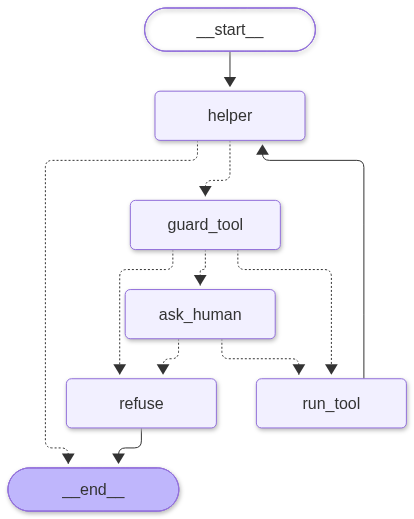

In [12]:
from IPython.display import Image, display

display(Image(app.get_graph().draw_mermaid_png()))

## Step 3 — Run it: the graph pauses

A checkpointer needs a `thread_id` so it knows which conversation to save and resume.


In [13]:
config: RunnableConfig = {"configurable": {"thread_id": "admin-delete-1"}}

result: dict[str, Any] = app.invoke({"role": "admin", "message": "delete the record"}, config)

print("Paused at:", app.get_state(config).next)
print("Question for the human:", result["__interrupt__"][0].value)

Paused at: ('ask_human',)
Question for the human: {'question': "Allow 'delete' for role 'admin'?", 'message': 'delete the record', 'options': ['approve', 'reject']}


## Step 4 — The human approves


In [14]:
result = app.invoke(Command(resume="approve"), config)
print(result["answer"])

Here you go: record deleted


## Step 5 — A different run, the human rejects


In [15]:
config_2: RunnableConfig = {"configurable": {"thread_id": "admin-delete-2"}}

app.invoke({"role": "admin", "message": "delete the record"}, config_2)
result = app.invoke(Command(resume="reject"), config_2)
print(result["answer"])

Blocked! Reason: a human rejected the action


## Step 6 — Guards still run first


In [16]:
def run(role: str, message: str, thread_id: str) -> str:
    """Run once. If the graph pauses, report it instead of answering."""
    cfg: RunnableConfig = {"configurable": {"thread_id": thread_id}}
    out: dict[str, Any] = app.invoke({"role": role, "message": message}, cfg)

    if "__interrupt__" in out:
        return "⏸ waiting for human approval"
    return out["answer"]


print("viewer delete ->", run("viewer", "delete the record", "t-viewer"))  # Guard 2 says NO, no human bothered
print("viewer search ->", run("viewer", "search cheap flights", "t-search"))  # safe tool, no approval needed
print("admin delete  ->", run("admin", "delete the record", "t-admin"))

viewer delete -> Blocked! Reason: not allowed to use delete
viewer search -> Here you go: 3 cheap flights found.
admin delete  -> ⏸ waiting for human approval


## Takeaways

- Automatic guards first; **humans only for risky, irreversible actions** (or they'll click "approve" on autopilot).
- `interrupt()` + checkpointer + `Command(resume=...)` = pause, save, continue.
- Use a real database checkpointer (Postgres, SQLite) in production so approvals survive restarts.
- Keep the node before `interrupt()` side-effect free — it runs again on resume.

**Next episode:** putting every guard together into one pipeline.
